# Tumor-edge：3,000 基因背景与稀疏通讯变化

选择 **cccphe**，执行 **Restart Kernel → Run All**。这是独立实验，原模拟和原 Notebook 保留。8,000 个细胞、五种类型、四个真实 MI、32 维 Z；沿用原 KNN30、sigma=20 µm 和 CCC 定义。

**背景：**3,000 个编码器基因，其中 150 个 LR 基因、25 个标记基因、1,200 个类型模块基因、800 个共享状态基因和 825 个管家基因。背景通过 scCube 生成并进行显式类型均值校准，再加入共享状态、文库大小和负二项变异；这些是公开记录的模拟假设。两个半环的类型、径向位置和原始非 LR 表达逐对匹配。

**区域通讯活性：**Tumor core 的 MI-3、Normal exterior 的 MI-4 在各自区域内为 1，取消原来额外的 50 µm 边界衰减。两个边缘 MI 不变；KNN 混合仍产生真实的边界过渡。旧数据与旧结果保留，新场景重新计算 CCC 并训练所有方法。

**通讯注入：**两个边缘 MI 涉及 24 个基因（面板的 0.8%）；sender ligand/receiver receptor 由独立潜在表达率注入（弱基础率 0.15＋峰值增量 3），未分配 LR 使用类型相关背景；使用一次 Gamma–Poisson 计数抽样和独立 MI 增量，允许零表达细胞被激活。训练细胞类型内表达覆盖率 ≥10%，先确定有效监督 mask 再拟合 CCC 尺度。只修改真实表达，不修改 CCC 矩阵。文库归一化可能带来小幅间接背景差异，实际 LR 计数比例等审计写入 NAS。此实验不是严格的 spatial-pairing-only 模拟，也不保证某种方法获胜。

**模型：**NMF 初始化后的 CCC-only 阶段只有 CCC＋正则影响 Z，基因 decoder 拟合时冻结 Z。另行记录受保护的联合尝试（表达梯度上限 10%，验证 CCC 波动上限 0.5%），只有 CCC 保护与基因验证改善同时通过才采纳，否则保留冻结起点。额外 24 个模拟响应基因和 12 个阴性对照只作表达标签，不进入编码器。**Niche 分配：**聚类表示保留 80% 自身、加入 20% 现有距离权重下的邻居表示，再用完整 KMeans；训练/验证/测试的物理细胞隔离保持。只调整聚类，不改变模型、Z、H、CCC 或基因重构。自动 K=4–15 使用同一调整后的表示。图表保持原 Notebook 的顺序，末尾比较 GraphST、CellCharter(scVI)、scNiche、NicheCompass、SpaNiche、BANKSY 和 STAGATE。完整数据、模型和图片均写入新的 NAS 输出目录，已完成且一致的结果可复用。

In [1]:
%matplotlib inline
from pathlib import Path
import sys,contextlib,json
import matplotlib.pyplot as plt
import torch
from IPython.display import display
ROOT=Path('/home/xueshuailin/CCC_Phe')
sys.path.insert(0,str(ROOT/'src'))
from phenoniche.simulation.dependencies import prepare_environment
from phenoniche.simulation.response_simulation import ExpressionExperimentConfig
from phenoniche.simulation.response_experiment import run_expression_experiment
from phenoniche.simulation.joint_reporting import JointExpressionReport
from phenoniche.training import set_seed
from phenoniche.simulation.boundary_background import prepare_boundary_background
from phenoniche.simulation.niche_refinement import refine_saved_niches
config=ExpressionExperimentConfig.from_json(ROOT/'config/tumor_edge_gene_rich_expression.json')
MODEL_OUTPUT=Path(config.output_dir)
refinement=json.loads((ROOT/'config/tumor_edge_gene_rich_niche_refinement.json').read_text())
OUTPUT=Path(refinement['output_dir'])
OUTPUT.mkdir(parents=True,exist_ok=True)
torch.set_num_threads(6)
set_seed(config.seed)
if torch.cuda.is_available():torch.cuda.set_device(2)
if config.device.startswith('cuda:') and not torch.cuda.is_available():
    raise RuntimeError('请在服务器 cccphe GPU 环境中运行')
with (OUTPUT/'notebook_execution.log').open('a',buffering=1) as log,contextlib.redirect_stdout(log),contextlib.redirect_stderr(log):
    prepare_environment()
    prepare_boundary_background(config.base_simulation_config,ROOT/'config/tumor_edge_gene_rich_background.json')
    run_expression_experiment(config)
    refine_saved_niches(MODEL_OUTPUT,OUTPUT,refinement['mixing'])
report=JointExpressionReport(OUTPUT)
def show(fig):
    display(fig)
    plt.close(fig)

## 1. 模拟组织与模型 niche

显示原始聚类编号，不用真实标签替换模型输出。CCC-only 与联合模型使用相同数据，联合模型 K=4–15 的选择只用训练/验证集，不读取真实 niche。

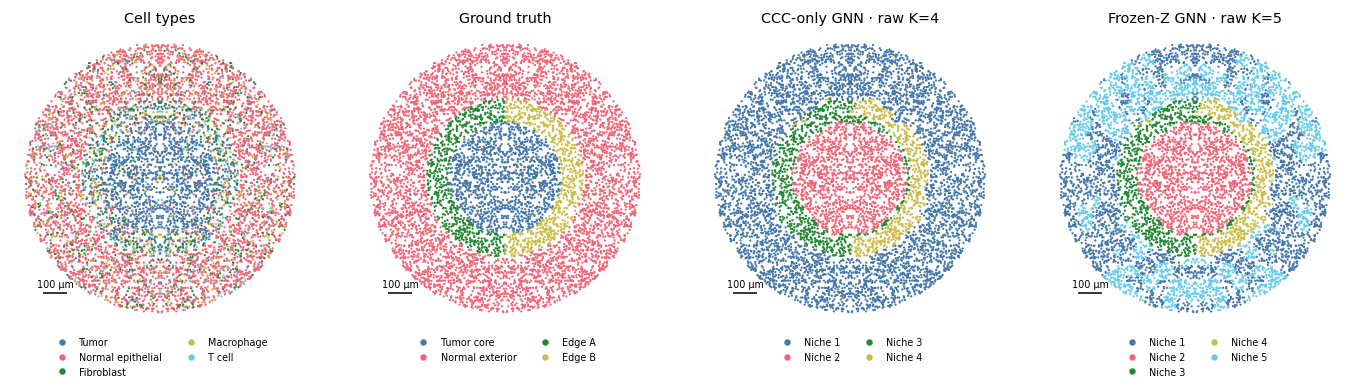

In [2]:
show(report.spatial_comparison())

## 2. 四个真实通讯程序是否恢复

上下两行使用相同数值尺度；下方由 **Z @ H** 沿预先定义的 MI 字典投影，汇总全部 32 个程序的贡献，不强制一个 MI 对应一个 Z 维度。真实字典只用于训练后的评估。

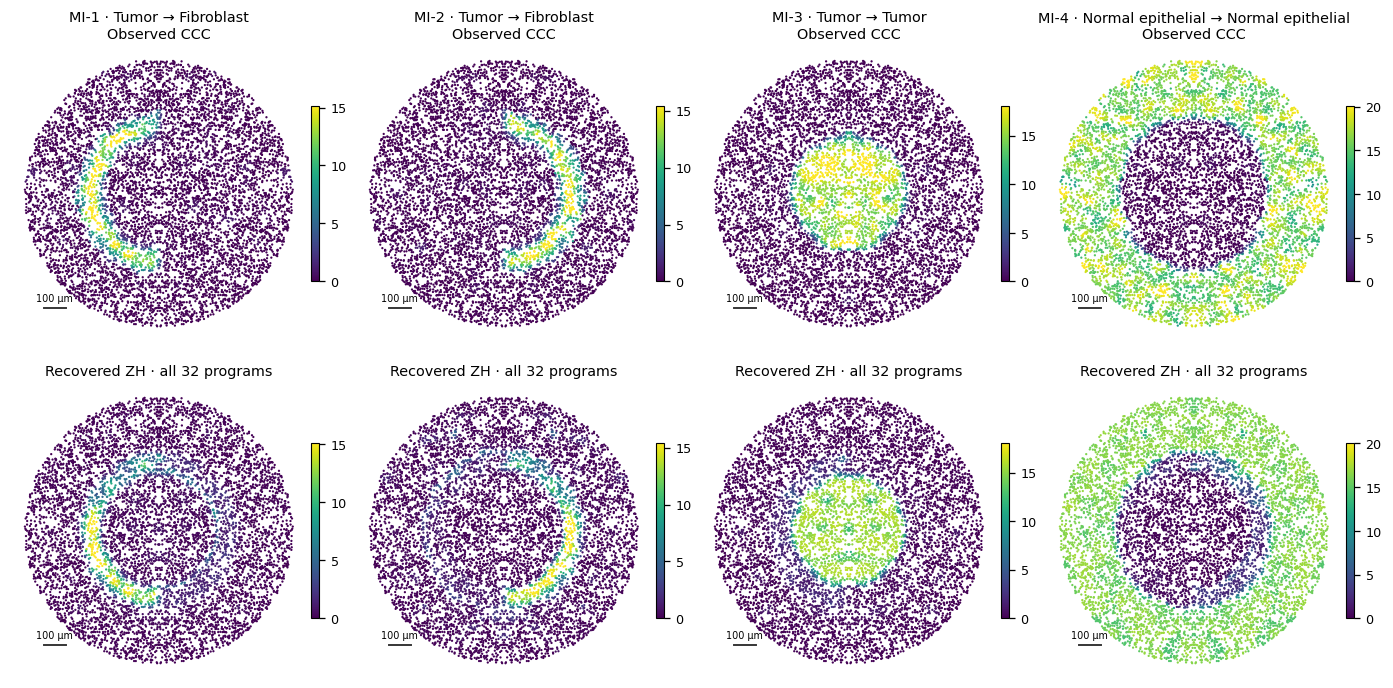

In [3]:
show(report.communication_recovery())

## 3. 基因表达是否对应

同一列是同一个模拟响应基因；每个 niche 内按该基因的 receiver 类型汇总空间加权表达，再减去该类型中这个基因的观测均值。上下两幅共用色标和参考均值，蓝色较低、红色较高。热图展示**全组织（含训练和验证中心）的描述性结果**。下方另用空间测试集对比基线、冻结版和联合版的 RMSE，并显示测试覆盖；严格两跳划分可能排除部分区域；下方测试覆盖图给出实际覆盖，不对未覆盖区域宣称独立验证。

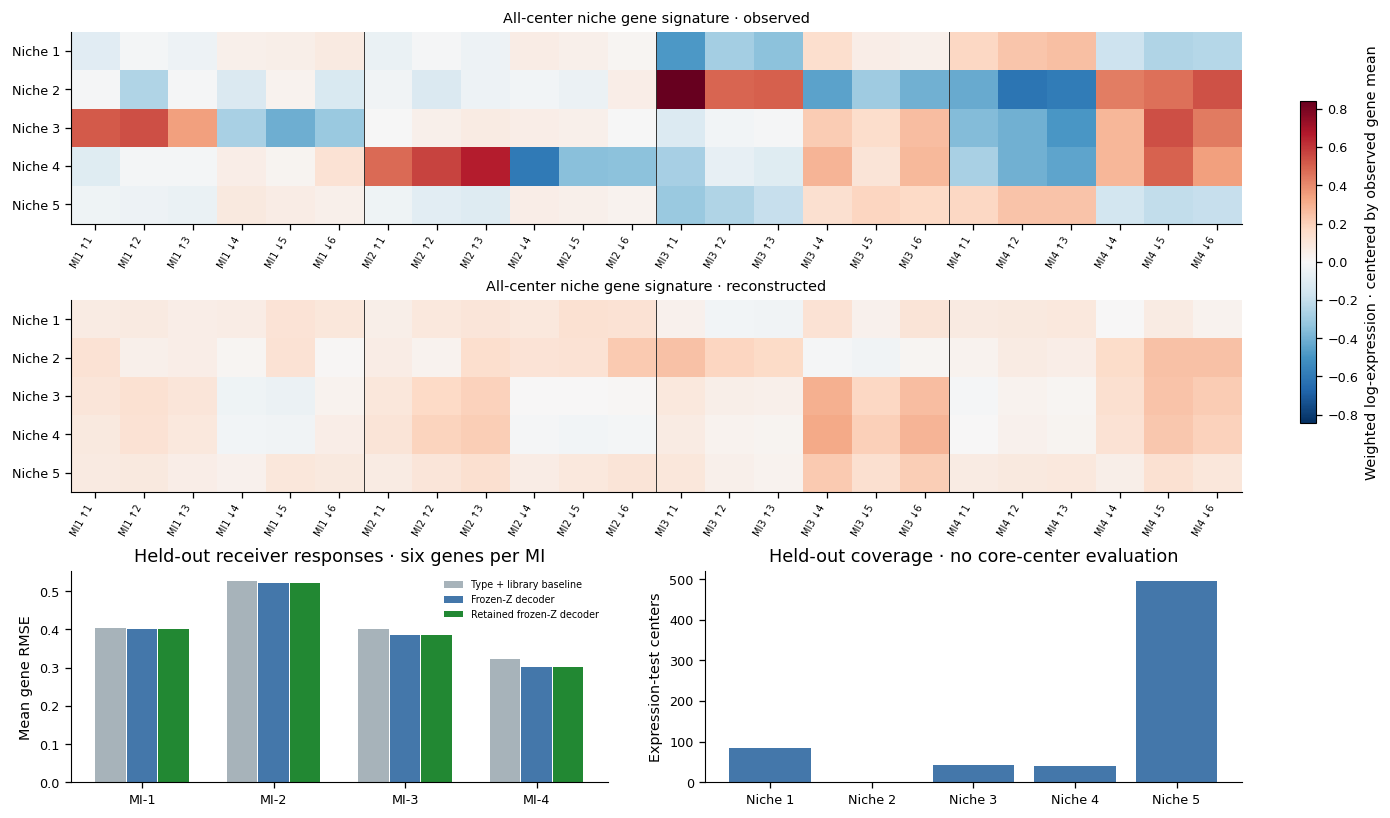

In [4]:
show(report.expression_recovery())

## 4. Niche 与细胞类型的关系

同一物理细胞对权重计算的空间加权组成。此图仅用于下游解释，不增加细胞组成重建损失。

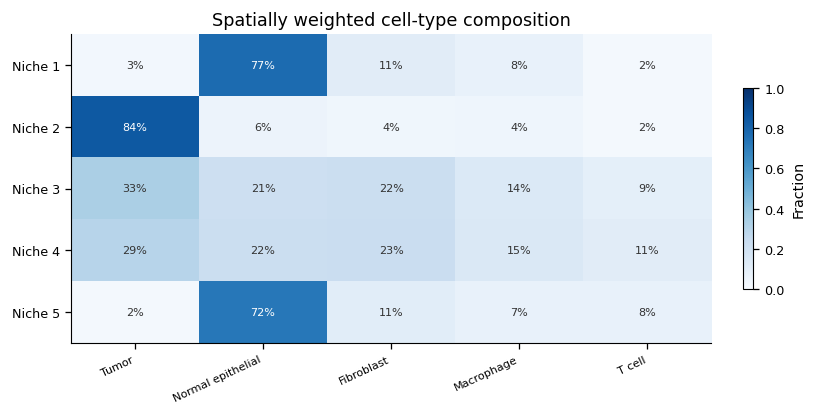

In [5]:
show(report.niche_cell_types())

## 5. 每个 niche 的 top10 CCC

对 niche 内 Z 取均值后乘 H：**mean(Z | niche) @ H**。表中列出 sender→receiver→LR、平均重构强度及贡献最大的程序；niche 可由多个程序共同形成。排序按原始 CCC 单位计算，不代表临床显著性或因果作用。

In [6]:
display(report.top_ccc.rename(columns={'niche':'Niche','rank':'Rank','sender':'Sender','receiver':'Receiver','LR':'Ligand–Receptor','mean_reconstructed_CCC':'Mean CCC','main_program':'Main program'}).drop(columns=['LR_id']).style.format({'Mean CCC':'{:.3f}'}).hide(axis='index'))

Niche,Rank,Sender,Receiver,Ligand–Receptor,Mean CCC,Main program
1,1,Normal epithelial,Normal epithelial,DEFB4A–CCR6,2.910,25
1,2,Normal epithelial,Normal epithelial,BMP10–BMPR1A,2.765,8
1,3,Normal epithelial,Normal epithelial,COL4A2–DDR2,2.699,1
1,4,Normal epithelial,Normal epithelial,APOB–LRP6,2.697,1
1,5,Normal epithelial,Normal epithelial,TSHB–ADRB3,2.684,1
1,6,Normal epithelial,Normal epithelial,DSC1–DSG2,2.684,1
1,7,Normal epithelial,Normal epithelial,PLAT–ITGB2,2.669,1
1,8,Normal epithelial,Normal epithelial,CCL25–CCR10,2.654,1
1,9,Normal epithelial,Normal epithelial,IAPP–RAMP1,2.439,8
1,10,Fibroblast,Fibroblast,FGF3–FGFR2,2.368,20


## 6. 训练 loss

分别显示 CCC 预训练和联合阶段的两个任务，数值尺度不同。虚线标出选中的 joint epoch，点线表示验证 CCC 的接受上限；epoch 0 是冻结版起点。

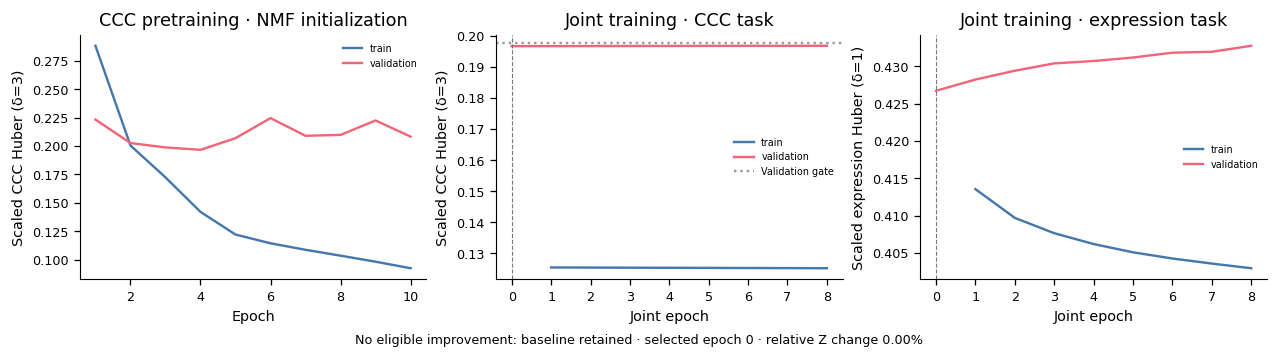

In [7]:
show(report.curves())

## 7. 模拟数据与模型结果总图

真实四区域、细胞类型、CCC-only 和联合 niche 并排显示；下方比较四个真实 MI 与恢复的通讯强度。**仅这张总图**使用训练中心拟合的标签颜色映射，便于直观对照；第一图和表中仍保留原始编号。底部指标由 held-out test 实际计算，标签匹配未进入训练或 K 选择。高分是本模拟、当前随机种子的结果，不是临床验证。全部 PNG/PDF/SVG、指标和模型数组在 NAS 输出目录。

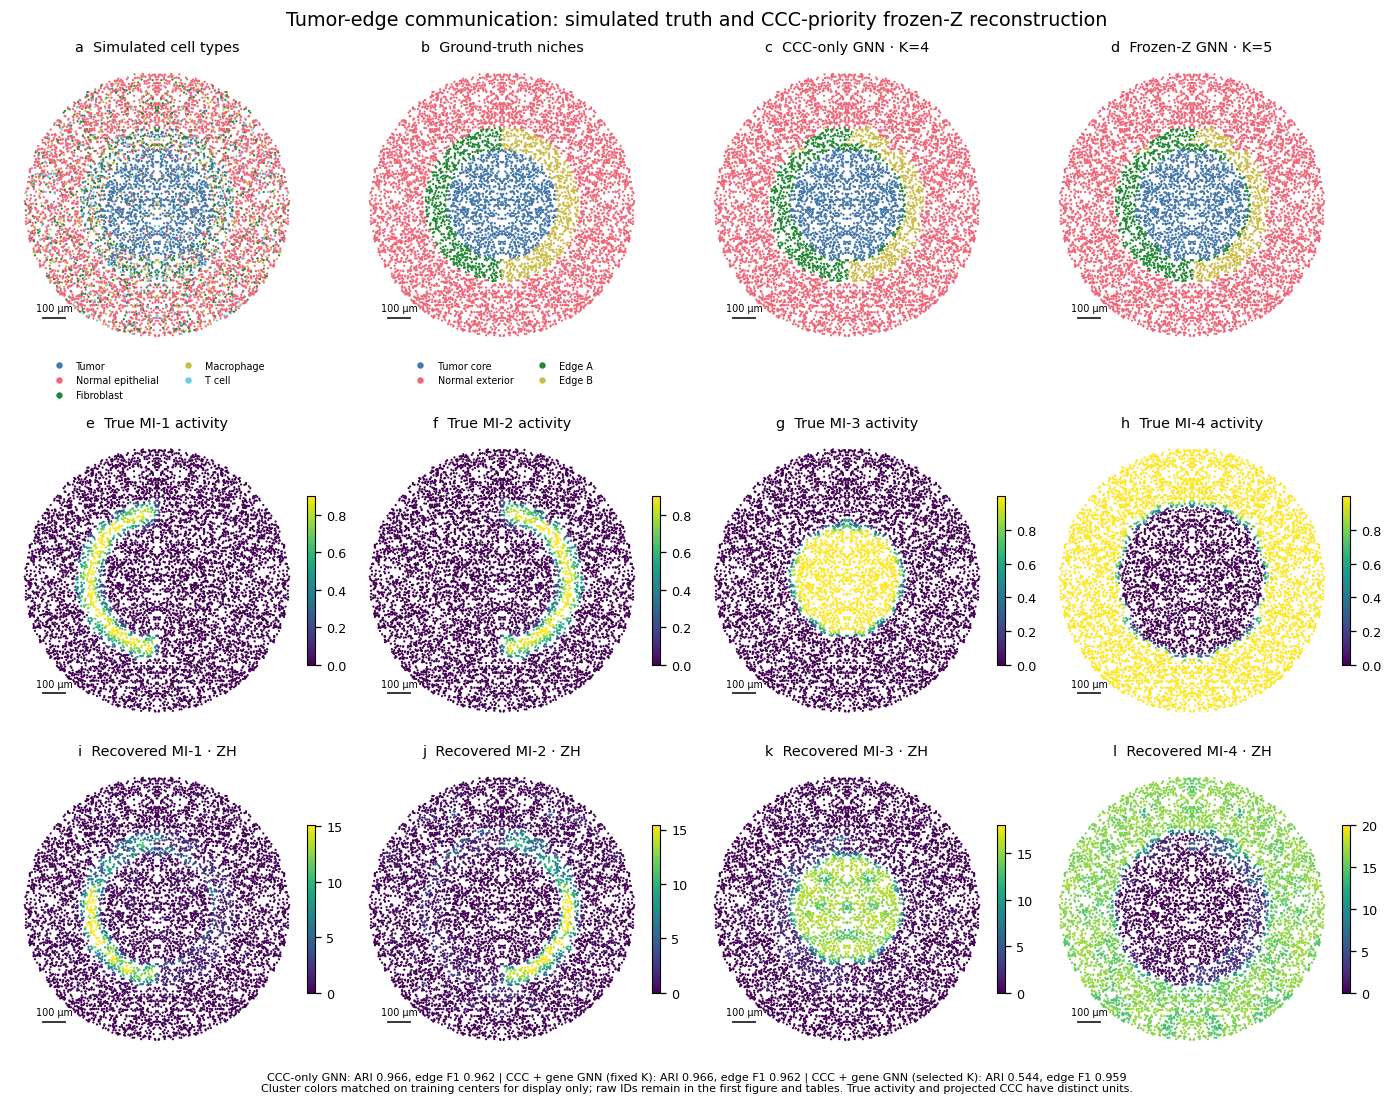

In [8]:
show(report.summary_figure())

## 8. 与空间聚类 baseline 比较

比较 [GraphST](https://github.com/JinmiaoChenLab/GraphST)、[CellCharter](https://github.com/CSOgroup/cellcharter)（官方 scVI 流程）、[scNiche](https://github.com/ZJUFanLab/scNiche)、[NicheCompass](https://github.com/Lotfollahi-lab/nichecompass)、[SpaNiche](https://github.com/SiyuanHuang1/SpaNiche)、[BANKSY](https://github.com/prabhakarlab/Banksy_py)、[STAGATE](https://github.com/RucDongLab/STAGATE_pyG)。使用固定版本的官方模型/训练核心；适配代码与来源记录在 `baselines/`。

**公平协议：**同一份新场景的 8,000 个细胞、3,000 个原始表达基因；新增响应基因不进入任何 baseline。表示模型、PCA、scVI、特征筛选及归一化只拟合原 GNN 训练物理细胞，聚类只拟合训练中心。所有主比较固定 K=4，使用同一批严格空间测试中心；不按真实区域标签调参。新表达场景重新训练各方法，旧数据上的分数不混入。

**保留各方法定义：**GraphST 为官方稀疏模型；CellCharter 为原始 counts 的 scVI（ZINB、10维）＋官方 Delaunay 图（三层聚合）＋官方 GMM；scVI 在独立兼容环境运行，所有方法统一测试集额外审计其三层邻域；scNiche 为中心表达、邻域表达、细胞组成的三视图 MGAE/GFN/MMIM。NicheCompass 为官方空间 VGAE，以整个公开 LR 库在真实基因面板中的交集构造 LR 程序，并保留 de novo 程序，使用官方 active-program 表示聚类；这是 LR-only prior 变体，不声称有合成基因的真实 TF/target 先验。SpaNiche 为官方 IntNMF 初始化＋图正则联合 NMF；单细胞类型替代 spot 去卷积，视图半径由训练 KNN30 尺度决定，Gaussian sigma=20 µm。其测试推理固定训练 H，再按原目标估计 W；官方 topic-argmax 原始结果也保存。

BANKSY 保留官方邻域均值与 centered AGF 表达梯度，采用组织分区参数 λ=0.8、K15/K30；训练邻居按物理 fold 隔离，标准化与 PCA 只拟合训练细胞；冻结后在完整组织图推理，统一测试集额外检查它实际使用的邻居。STAGATE 保留官方表达 MSE、图注意力与 decoder 权重共享，hidden=512、latent=30、1,000 epochs；仅训练空间区域内的诱导图用于优化，推理冻结权重。两者均使用完整的 3,000 基因，不使用细胞类型或 CCC。

**信息条件不同：**GraphST/CellCharter/BANKSY/STAGATE 使用表达与坐标；scNiche/SpaNiche 另使用观测细胞类型；NicheCompass/SpaNiche 另使用公开 LR 先验；CCC-AE 输入预计算 CCC，我们的 GNN 以 CCC 监督。真实 niche 标签、MI 活性及 MI loading 只用于拟合结束后的评价和配色。参数预算、依赖版本、适配差异与原始 cluster ID 均保存，不保证任何方法获胜。

In [9]:
sys.path.insert(0,str(ROOT))
from baselines.benchmark import run_comparison
from baselines.reporting import BaselineReport
with (OUTPUT/'baseline_comparison_execution.log').open('a',buffering=1) as log,contextlib.redirect_stdout(log),contextlib.redirect_stderr(log):
    BASELINE_OUTPUT=run_comparison(OUTPUT)
    baseline_report=BaselineReport(OUTPUT,BASELINE_OUTPUT)

### 空间聚类图

第一图保留各方法的原始 cluster ID；第二图仅为看图方便，用训练中心拟合颜色映射。真实标签均在拟合结束后才用于评价，不能把配色匹配当成预测。所有图含训练区域，下方 ARI 是全组织描述性恢复指标。

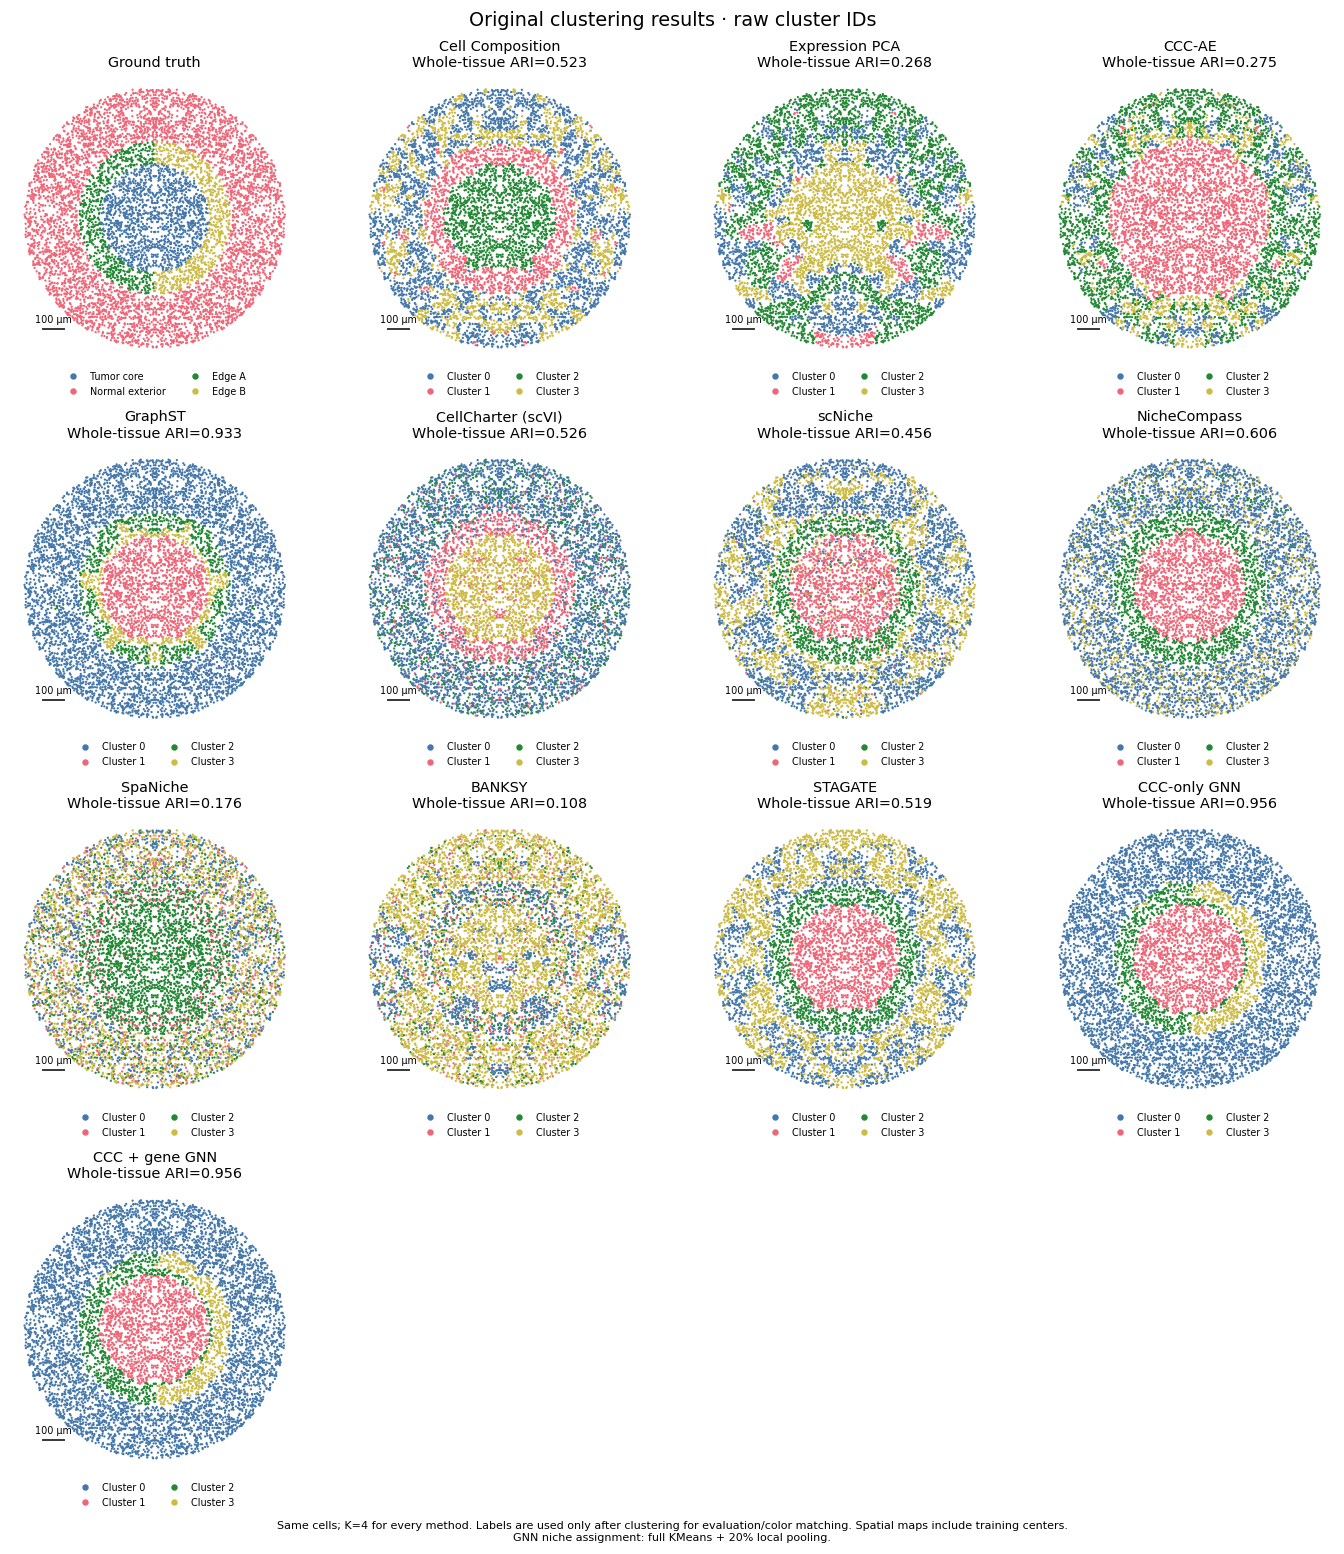

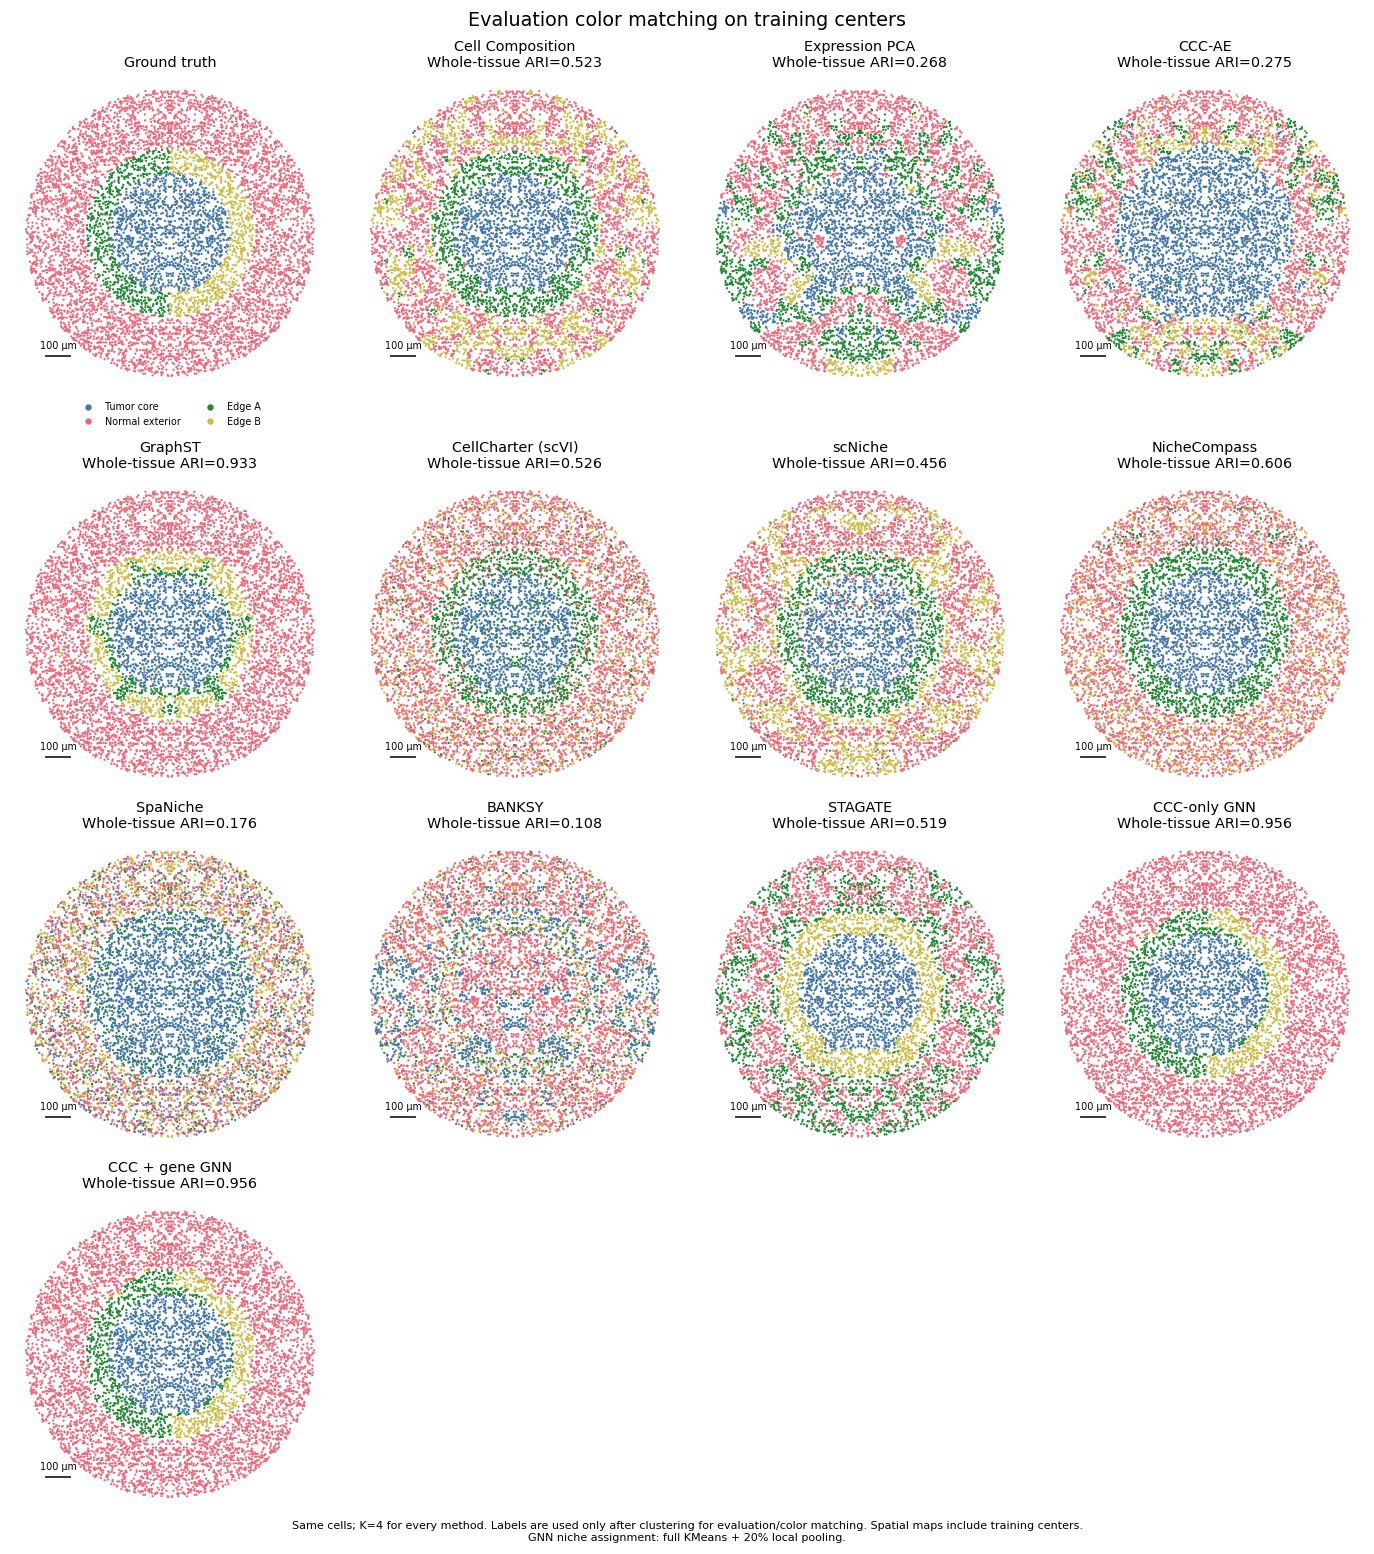

In [10]:
show(baseline_report.spatial(align=False))
show(baseline_report.spatial(align=True))

### 同一批空间测试中心上的评价

GraphST 的重构需要两跳图输入，因此所有方法统一使用原空间测试划分再加两跳隔离的中心集合。表中 `n`、`n_true_edge` 给出实际覆盖；未覆盖的区域不宣称已独立验证。ARI/NMI 使用原始聚类编号；F1/IoU 和 A/B accuracy 的映射只在训练中心拟合。固定 K=4 是预先定义的公平比较，不是无监督发现区域数的证据。当前只有一个模拟/训练随机种子，结果用于框架比较。

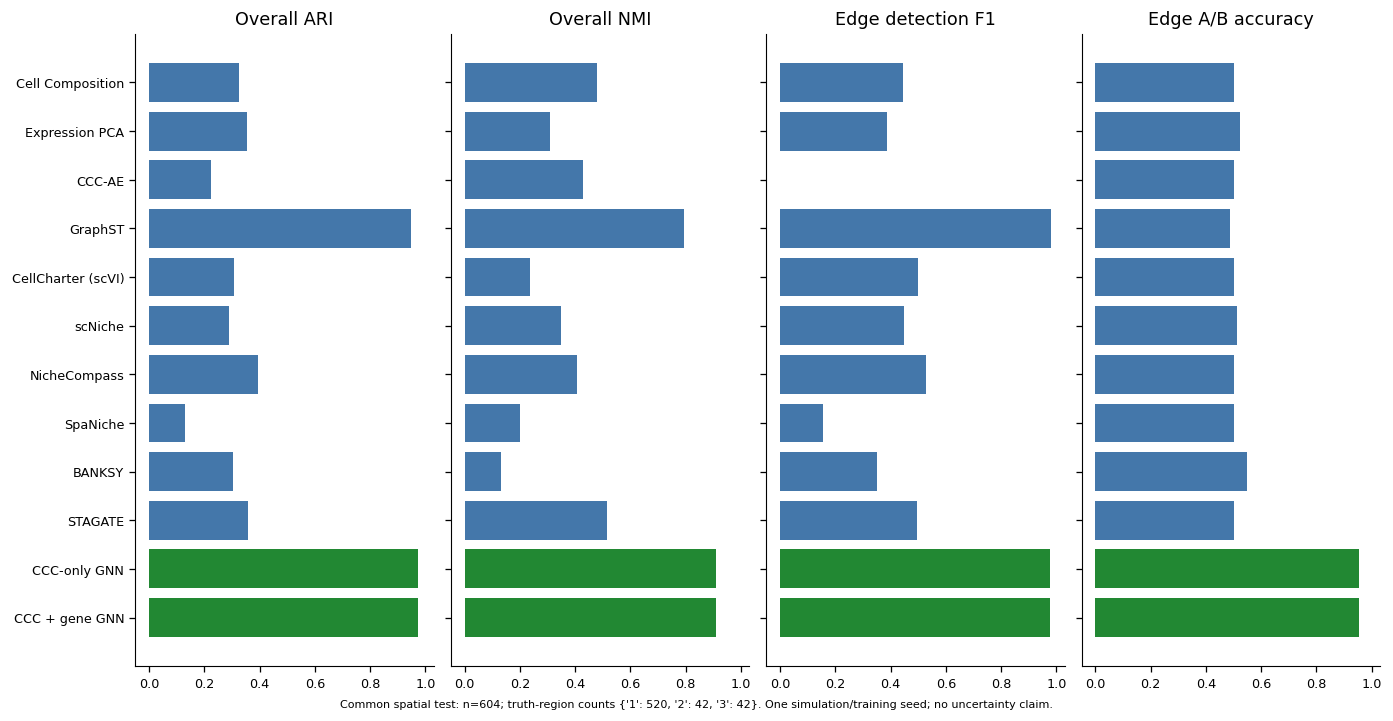

method,K,n,n_true_edge,overall_ARI,overall_NMI,edge_F1,edge_IoU,edge_AB_ARI,edge_AB_accuracy
Cell Composition,4,604,84,0.325,0.478,0.444,0.286,-0.002,0.500
Expression PCA,4,604,84,0.354,0.308,0.388,0.240,-0.016,0.524
CCC-AE,4,604,84,0.225,0.430,0.000,0.000,0.000,0.500
CCC-only GNN,4,604,84,0.972,0.910,0.976,0.952,0.817,0.952
CCC + gene GNN,4,604,84,0.972,0.910,0.976,0.952,0.817,0.952
GraphST,4,604,84,0.949,0.794,0.982,0.965,-0.004,0.488
CellCharter (scVI),4,604,84,0.308,0.238,0.500,0.333,-0.009,0.500
CellCharter (scVI; common KMeans),4,604,84,0.533,0.621,0.651,0.483,0.000,0.500
scNiche,4,604,84,0.290,0.347,0.447,0.288,-0.001,0.512
NicheCompass,4,604,84,0.393,0.407,0.527,0.357,-0.005,0.500


In [11]:
show(baseline_report.metric_plot())
display(baseline_report.metric_table().style.format({k:'{:.3f}' for k in ['overall_ARI','overall_NMI','edge_F1','edge_IoU','edge_AB_ARI','edge_AB_accuracy']}).hide(axis='index'))

### 全组织描述性指标与计算条件

此表补充包括核心区在内的全组织恢复效果，含训练中心，不能解释成独立泛化评估。空间 baseline 没有 directed CCC decoder，因此不编造其 CCC 重构指标。方法原始输出、checkpoint、输入基因、严格公共测试划分、软件版本和官方源码 commit 均保存在 NAS 中。

In [12]:
display(baseline_report.metrics.query("scope == 'all_centers_descriptive'")[['method','K','n','overall_ARI','overall_NMI','edge_F1','edge_AB_accuracy']].style.format({k:'{:.3f}' for k in ['overall_ARI','overall_NMI','edge_F1','edge_AB_accuracy']}).hide(axis='index'))

method,K,n,overall_ARI,overall_NMI,edge_F1,edge_AB_accuracy
Cell Composition,4,8000,0.523,0.640,0.564,0.500
Expression PCA,4,8000,0.268,0.273,0.330,0.507
CCC-AE,4,8000,0.275,0.466,0.004,0.501
CCC-only GNN,4,8000,0.956,0.871,0.952,0.889
CCC + gene GNN,4,8000,0.956,0.871,0.952,0.889
GraphST,4,8000,0.933,0.805,0.947,0.504
CellCharter (scVI),4,8000,0.526,0.519,0.570,0.500
CellCharter (scVI; common KMeans),4,8000,0.625,0.725,0.651,0.501
scNiche,4,8000,0.456,0.521,0.527,0.514
NicheCompass,4,8000,0.606,0.675,0.654,0.501
